# Análise exploratória das camadas de solo (SoilGrids) por microrregião

Objetivos:
1. Descrever como cada propriedade varia com a profundidade.
2. Medir o quanto as camadas de uma mesma propriedade são correlacionadas.
3. Avaliar a redundância entre propriedades (correlação e PCA).

Os dados têm 558 microrregiões e 13 propriedades em 6 camadas (0–5, 5–15, 15–30, 30–60, 60–100 e 100–200 cm), mais `ocs` (estoque de carbono, só 0–30 cm).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

In [2]:
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

In [3]:
PROCESSED_DIR = Path("../../data/processed")
df = pd.read_parquet(PROCESSED_DIR / "solo_microrregioes_limpo_completo.parquet")

ids = df["CD_MICRO"]
X = df.drop(columns="CD_MICRO")

CAMADAS = ["0-5cm", "5-15cm", "15-30cm", "30-60cm", "60-100cm", "100-200cm"]
PROPS = sorted({c.split("_")[0] for c in X.columns if c != "ocs_0-30cm_mean"})

def col(p, l):
    return f"{p}_{l}_mean"

print(df.shape, "| nulos:", int(X.isna().sum().sum()), "| microrregiões únicas:", ids.nunique())
print("Propriedades:", PROPS)

(558, 80) | nulos: 0 | microrregiões únicas: 558
Propriedades: ['bdod', 'cec', 'cfvo', 'clay', 'nitrogen', 'ocd', 'phh2o', 'sand', 'silt', 'soc', 'wv0010', 'wv0033', 'wv1500']


## 1. Verificações básicas
Textura: `sand + silt + clay` deve somar cerca de 1000 g/kg em cada camada. Isso implica colinearidade perfeita entre as três.

In [4]:
fech = pd.DataFrame({l: X[col("sand", l)] + X[col("silt", l)] + X[col("clay", l)] for l in CAMADAS})
fech.describe().loc[["mean", "min", "max"]].round(1)

,0-5cm,5-15cm,15-30cm,30-60cm,60-100cm,100-200cm
mean,1000.0,1000.0,1000.0,1000.0,1000.0,1000.0
min,1000.0,1000.0,1000.0,1000.0,1000.0,1000.0
max,1000.1,1000.2,1000.2,1000.2,1000.2,1000.2


## 2. Estatísticas por camada

In [5]:
linhas = []
for p in PROPS:
    for l in CAMADAS:
        s = X[col(p, l)]
        linhas.append(dict(var=p, camada=l, media=s.mean(), dp=s.std(), cv=s.std() / s.mean(), min=s.min(), max=s.max()))
est = pd.DataFrame(linhas)
media = est.pivot(index="var", columns="camada", values="media")[CAMADAS]
cv = est.pivot(index="var", columns="camada", values="cv")[CAMADAS]
display(media.round(1))
display(cv.round(3))

camada,0-5cm,5-15cm,15-30cm,30-60cm,60-100cm,100-200cm
var,,,,,,
bdod,121.1,124.3,127.6,130.3,132.0,132.8
cec,163.1,141.3,132.7,129.8,125.9,122.7
cfvo,74.2,77.8,82.4,95.8,107.5,119.4
clay,305.7,309.3,345.2,399.4,404.4,398.3
nitrogen,250.0,174.4,129.5,90.8,70.2,57.3
ocd,331.5,251.0,188.2,105.9,63.5,43.6
phh2o,54.3,54.2,54.2,54.6,55.0,55.3
sand,458.6,457.1,429.9,389.7,385.7,391.3
silt,235.8,233.7,224.8,210.8,209.9,210.3


camada,0-5cm,5-15cm,15-30cm,30-60cm,60-100cm,100-200cm
var,,,,,,
bdod,0.091,0.087,0.079,0.084,0.086,0.086
cec,0.255,0.275,0.315,0.335,0.344,0.356
cfvo,0.421,0.434,0.427,0.400,0.375,0.372
clay,0.269,0.268,0.216,0.183,0.187,0.189
nitrogen,0.398,0.337,0.338,0.355,0.378,0.426
ocd,0.277,0.214,0.245,0.201,0.178,0.246
phh2o,0.093,0.090,0.089,0.084,0.077,0.077
sand,0.261,0.260,0.257,0.264,0.271,0.273
silt,0.267,0.263,0.266,0.260,0.254,0.251


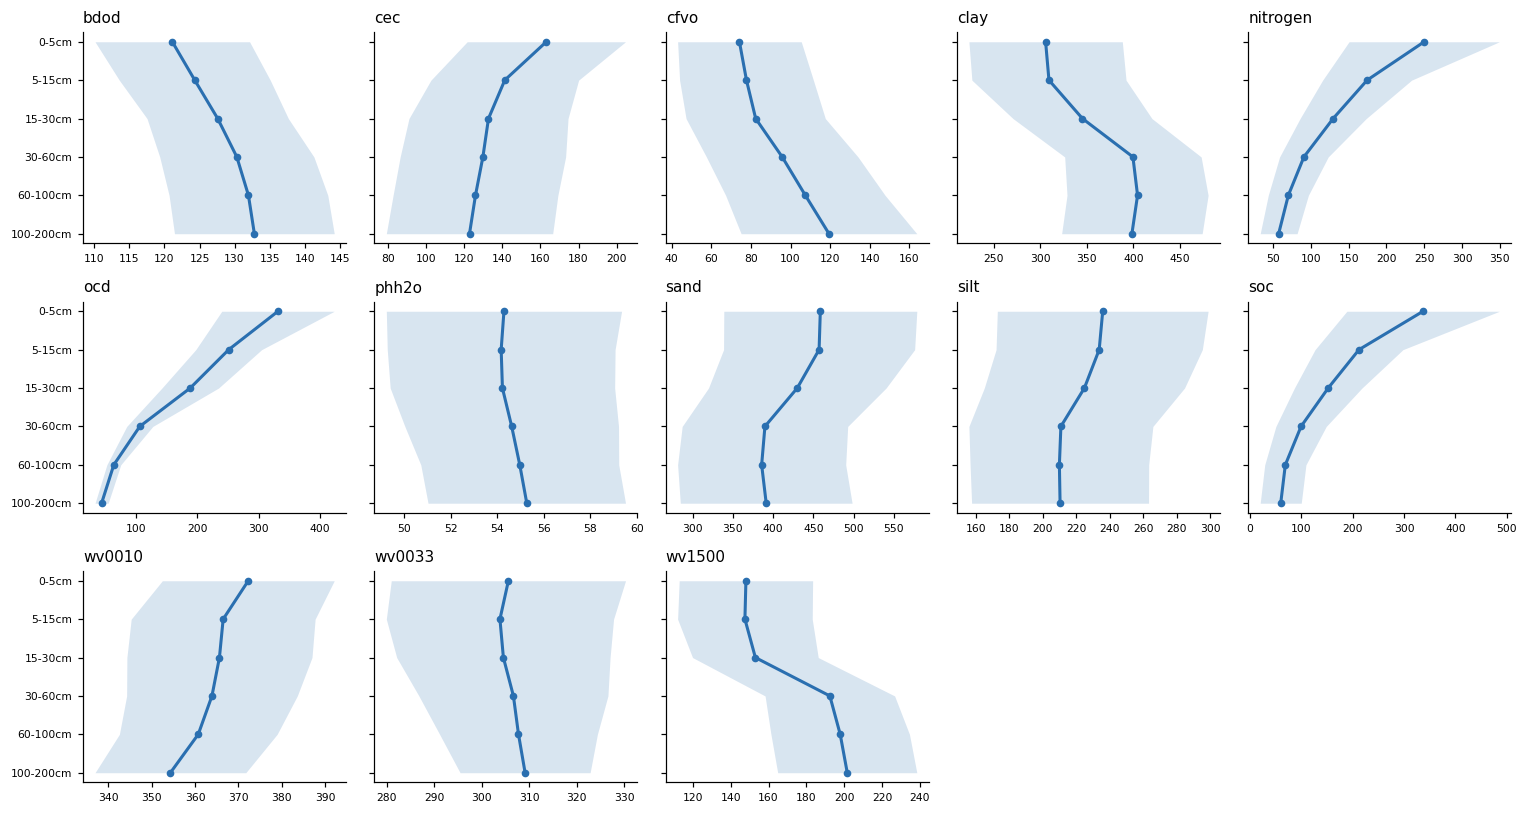

In [6]:
fig, axs = plt.subplots(3, 5, figsize=(14, 7.5), sharey=True)
y = np.arange(len(CAMADAS))
for ax, p in zip(axs.ravel(), PROPS):
    m = np.array([X[col(p, l)].mean() for l in CAMADAS])
    s = np.array([X[col(p, l)].std() for l in CAMADAS])
    ax.fill_betweenx(y, m - s, m + s, color="#2a6fb0", alpha=.18, lw=0)
    ax.plot(m, y, color="#2a6fb0", lw=2, marker="o", ms=4)
    ax.set_title(p, loc="left", fontsize=10)
    ax.set_yticks(y, CAMADAS, fontsize=7)
    ax.tick_params(axis="x", labelsize=7)
ax.invert_yaxis()
for ax in axs.ravel()[len(PROPS):]:
    ax.axis("off")
fig.tight_layout()
plt.show()

In [7]:
resumo = []
corr_camadas = {}
iu = np.triu_indices(len(CAMADAS), 1)
for p in PROPS:
    d = X[[col(p, l) for l in CAMADAS]]
    d.columns = CAMADAS
    cp, cs = d.corr(), d.corr("spearman")
    corr_camadas[p] = cp
    resumo.append(dict(
        var=p,
        pearson_min=cp.values[iu].min(),
        spearman_min=cs.values[iu].min(),
        vizinhas_media=np.mean([cp.values[i, i + 1] for i in range(5)]),
        topo_vs_fundo=cp.loc["0-5cm", "100-200cm"],
    ))
resumo = pd.DataFrame(resumo).set_index("var").sort_values("pearson_min")
resumo.round(3)

,pearson_min,spearman_min,vizinhas_media,topo_vs_fundo
var,,,,
ocd,0.539,0.517,0.896,0.543
bdod,0.580,0.546,0.974,0.580
soc,0.735,0.865,0.949,0.735
nitrogen,0.783,0.737,0.932,0.843
wv0010,0.860,0.821,0.980,0.860
wv0033,0.864,0.854,0.978,0.864
cec,0.896,0.914,0.987,0.896
cfvo,0.899,0.917,0.992,0.899
clay,0.906,0.890,0.982,0.923


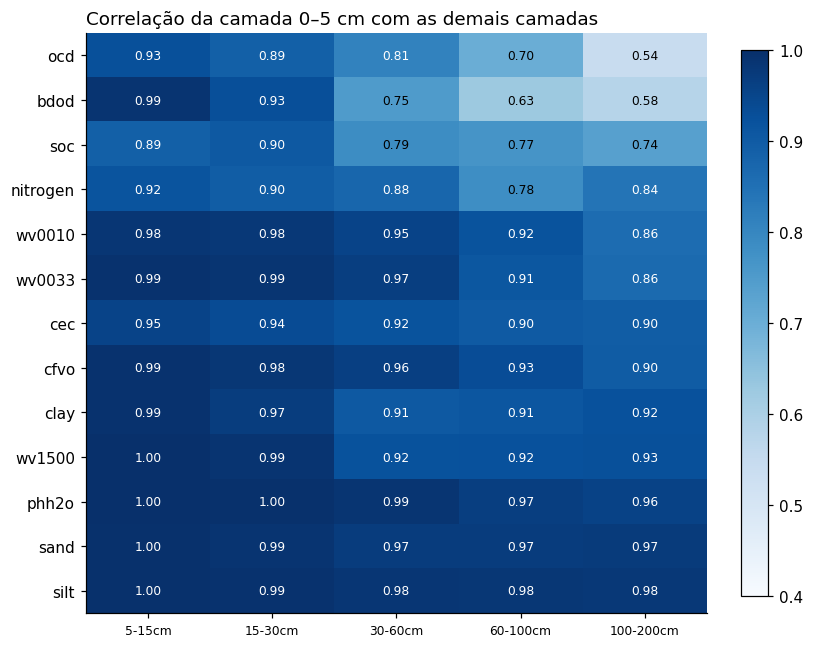

In [8]:
# Correlação da camada 0–5 cm com as demais
R = pd.DataFrame({p: [X[col(p, "0-5cm")].corr(X[col(p, l)]) for l in CAMADAS[1:]] for p in PROPS}, index=CAMADAS[1:]).T
R = R.loc[R["100-200cm"].sort_values().index]

fig, ax = plt.subplots(figsize=(7.5, 6))
im = ax.imshow(R, cmap="Blues", vmin=0.4, vmax=1, aspect="auto")
ax.set_xticks(range(5), R.columns, fontsize=8)
ax.set_yticks(range(len(R)), R.index)
for i in range(R.shape[0]):
    for j in range(R.shape[1]):
        v = R.values[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8, color="white" if v > .8 else "black")
ax.set_title("Correlação da camada 0–5 cm com as demais camadas", loc="left")
fig.colorbar(im, ax=ax, fraction=.04)
fig.tight_layout()
plt.show()

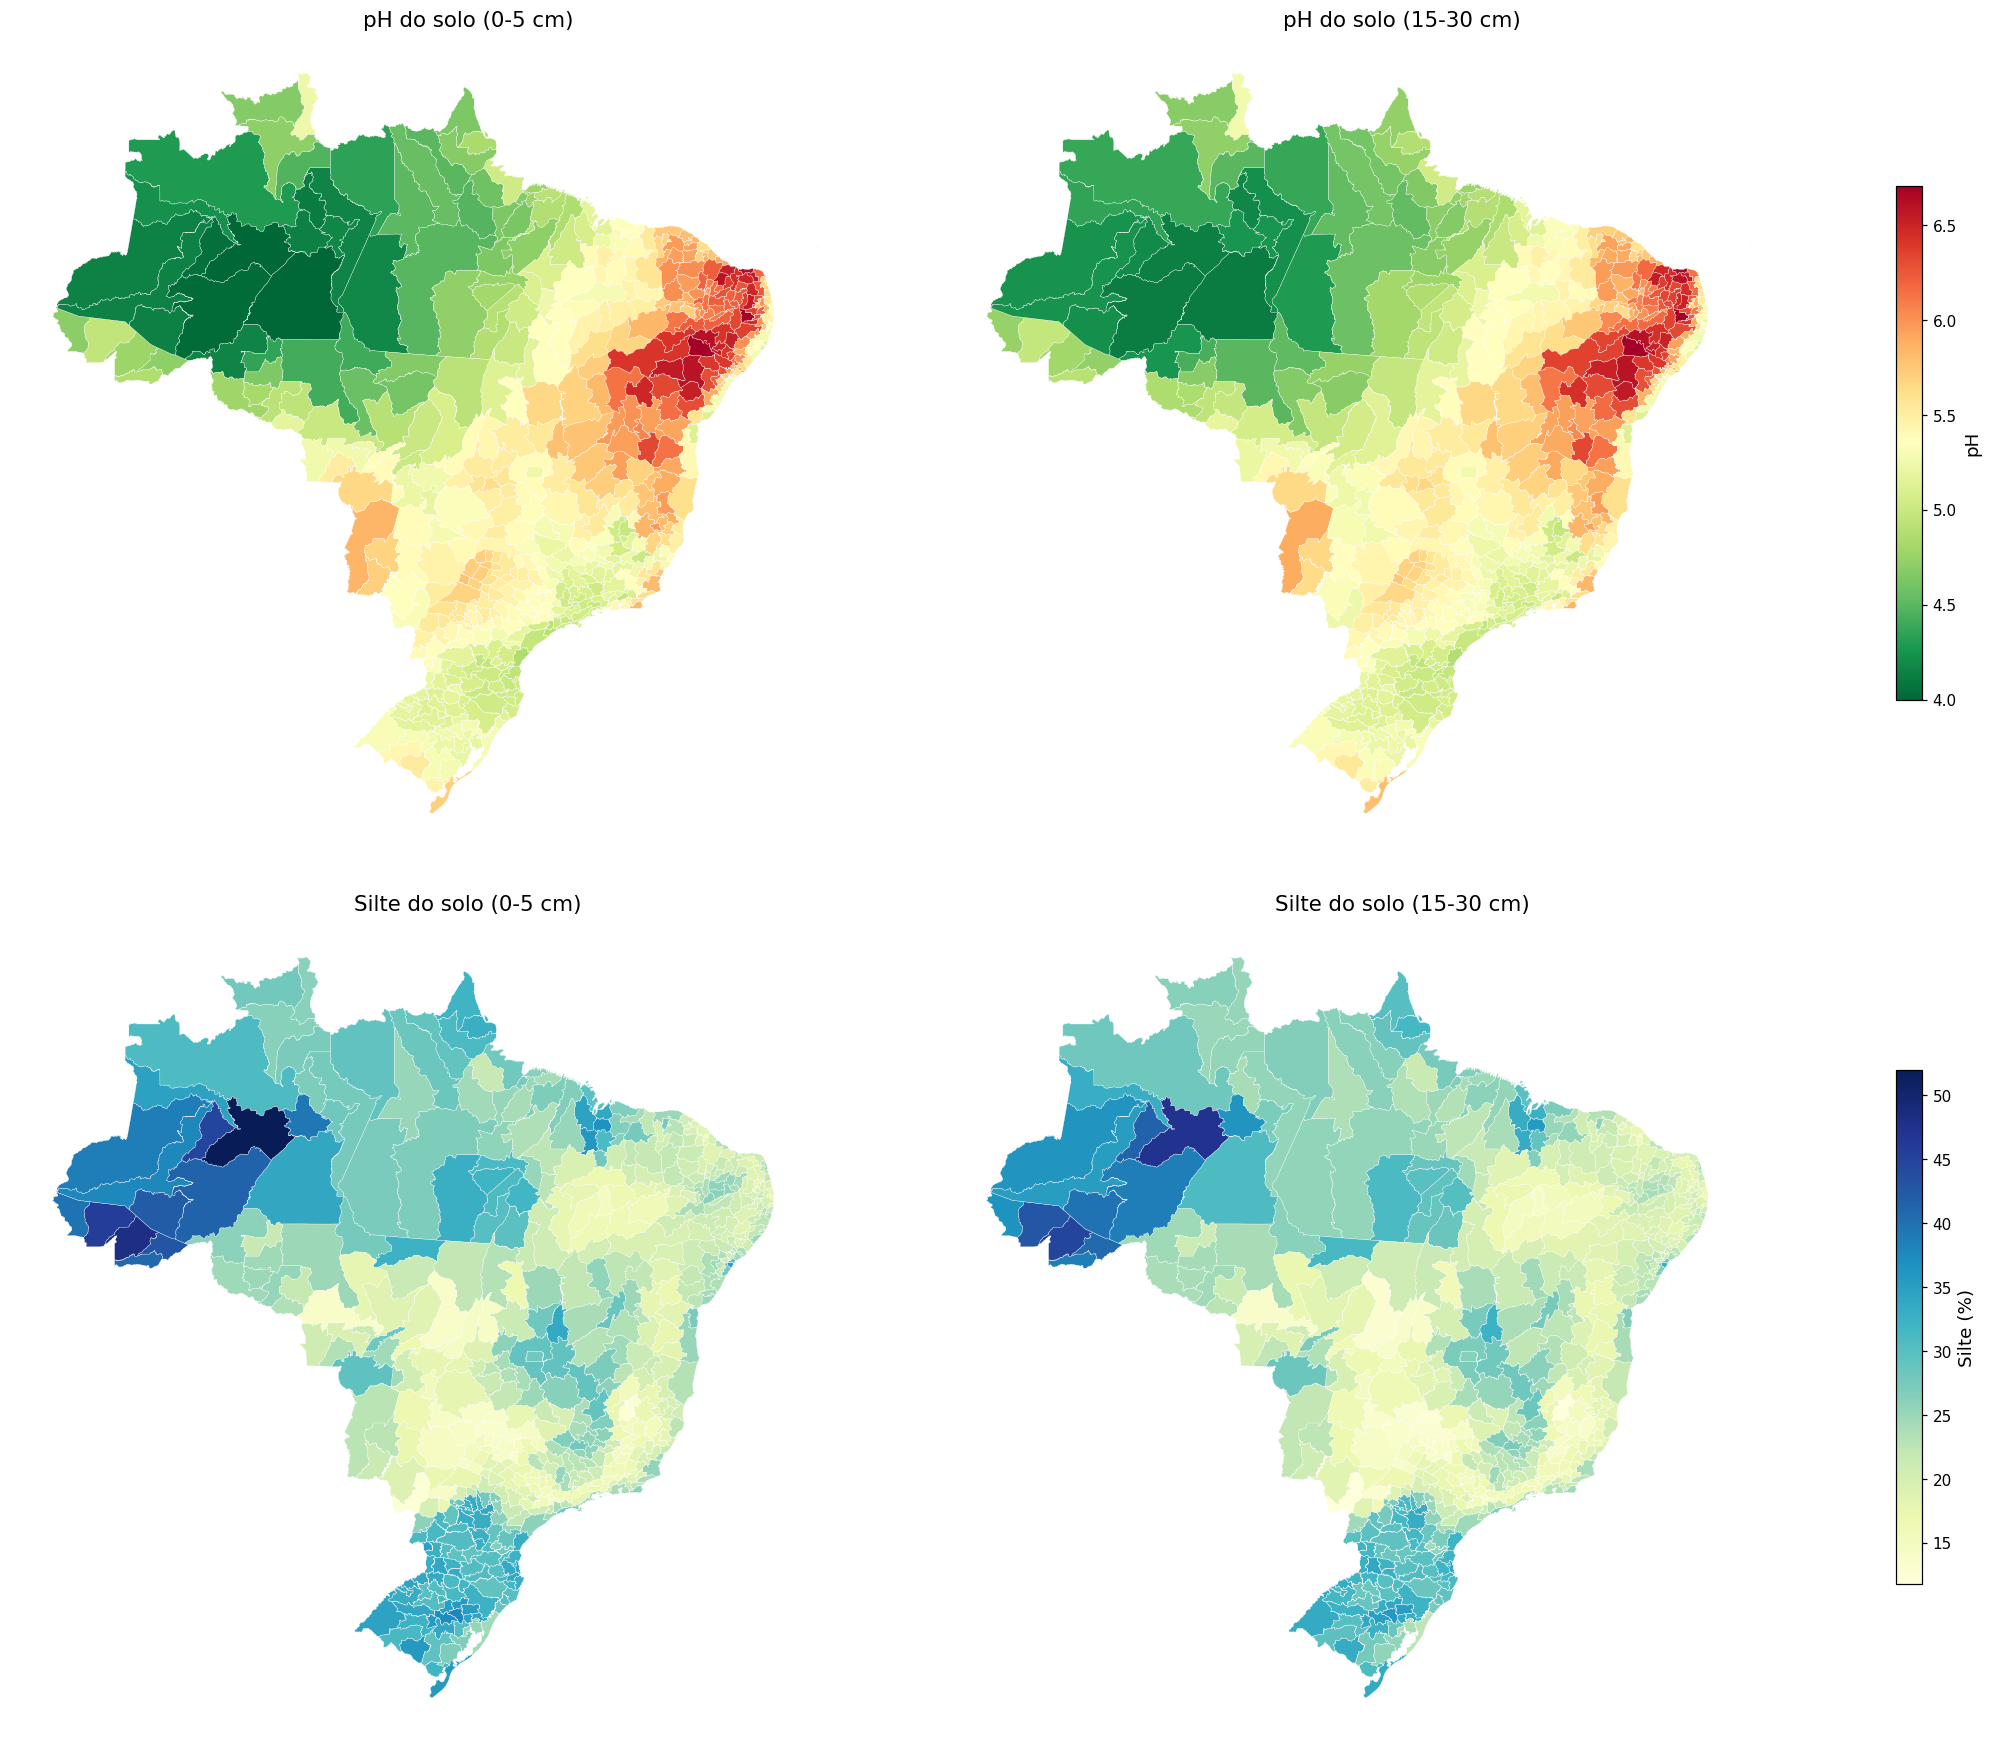

In [10]:
import geobr
import matplotlib.pyplot as plt
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize

# 1. Preparação dos dados (df_solo já carregado)
df['CD_MICRO'] = df['CD_MICRO'].astype(float).astype(int).astype(str)

# pH: o SoilGrids multiplica por 10; dividimos para obter o pH real
cols_ph = [c for c in df.columns if 'phh2o' in c]
df[cols_ph] = df[cols_ph] / 10.0

# Argila, areia e silte: g/kg -> %
cols_textura = [c for c in df.columns if any(x in c for x in ['clay', 'sand', 'silt'])]
df[cols_textura] = df[cols_textura] / 10.0

# 2. Mapa das microrregiões + merge
gdf_micro = geobr.read_micro_region(year=2020)
gdf_micro['code_micro'] = gdf_micro['code_micro'].astype(int).astype(str)
gdf_plot = gdf_micro.merge(df, left_on='code_micro', right_on='CD_MICRO', how='left')

# 3. Configuração dos mapas
# Linha = variável, coluna = camada. Cada linha tem UMA barra de cores compartilhada
# entre as duas camadas (mesma escala vmin/vmax), o que torna a comparação válida.
camadas = ['0-5cm', '15-30cm']
variaveis = {
    'phh2o': dict(nome='pH', cmap='RdYlGn_r', rotulo='pH'),
    'silt':  dict(nome='Silte', cmap='YlGnBu', rotulo='Silte (%)'),
}

fig, axes = plt.subplots(2, 2, figsize=(18, 16), layout='constrained')

for i, (var, cfg) in enumerate(variaveis.items()):
    colunas = [f'{var}_{c}_mean' for c in camadas]
    vmin = gdf_plot[colunas].min().min()
    vmax = gdf_plot[colunas].max().max()

    for j, (camada, coluna) in enumerate(zip(camadas, colunas)):
        ax = axes[i, j]
        gdf_plot.plot(
            column=coluna, cmap=cfg['cmap'], vmin=vmin, vmax=vmax, legend=False,
            ax=ax, edgecolor='white', linewidth=0.2,
            missing_kwds={'color': 'lightgrey'},
        )
        ax.set_title(f"{cfg['nome']} do solo ({camada.replace('cm', ' cm')})", fontsize=14)
        ax.axis('off')

    # Uma única barra de cores para o par de mapas da linha
    sm = ScalarMappable(norm=Normalize(vmin=vmin, vmax=vmax), cmap=cfg['cmap'])
    cbar = fig.colorbar(sm, ax=axes[i, :].tolist(), shrink=0.6, pad=0.02)
    cbar.set_label(cfg['rotulo'], fontsize=12)

# PNG com fundo transparente
fig.patch.set_alpha(0)
for ax in axes.ravel():
    ax.patch.set_alpha(0)
plt.savefig('mapas_ph_silte_0-5_vs_15-30.png', dpi=200, bbox_inches='tight', transparent=True)
plt.show()

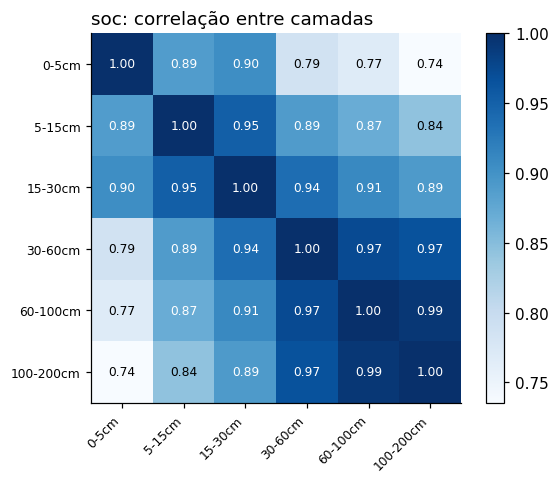

In [11]:
PROP = "soc"   # altere para qualquer item de PROPS

fig, ax = plt.subplots(figsize=(5.5, 4.5))
c = corr_camadas[PROP]
im = ax.imshow(c, cmap="Blues", vmin=c.values.min(), vmax=1)
ax.set_xticks(range(6), CAMADAS, rotation=45, ha="right", fontsize=8)
ax.set_yticks(range(6), CAMADAS, fontsize=8)
for i in range(6):
    for j in range(6):
        ax.text(j, i, f"{c.values[i, j]:.2f}", ha="center", va="center", fontsize=8,
                color="white" if c.values[i, j] > (c.values.min() + 1) / 2 else "black")
ax.set_title(f"{PROP}: correlação entre camadas", loc="left")
fig.colorbar(im, ax=ax, fraction=.046)
fig.tight_layout()
plt.show()

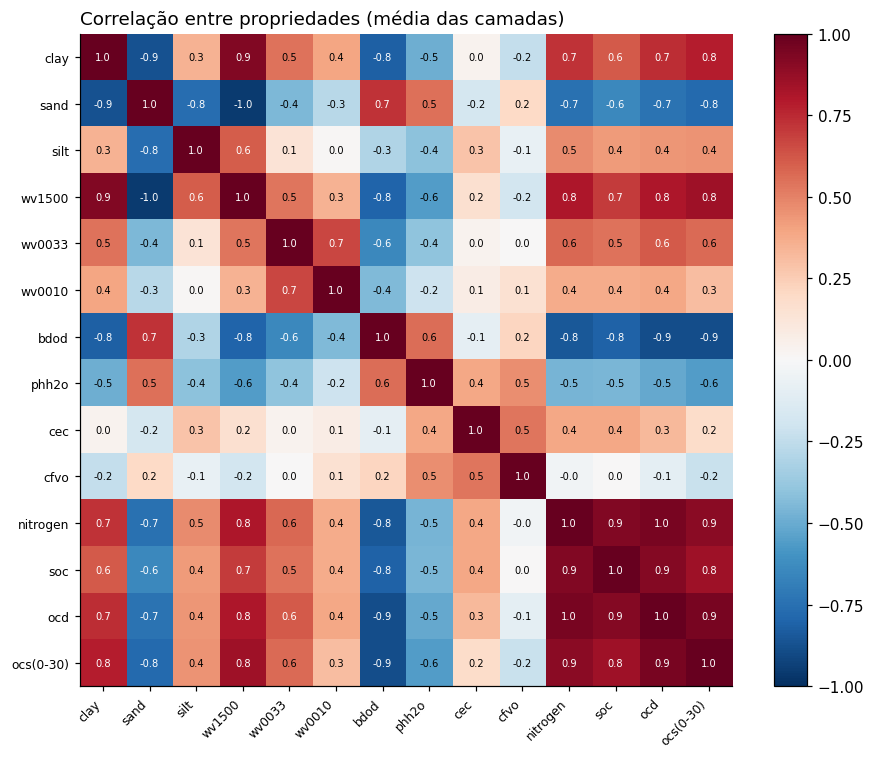

In [12]:
M = pd.DataFrame({p: X[[col(p, l) for l in CAMADAS]].mean(axis=1) for p in PROPS})
M["ocs(0-30)"] = X["ocs_0-30cm_mean"]
ordem = ["clay", "sand", "silt", "wv1500", "wv0033", "wv0010", "bdod", "phh2o", "cec", "cfvo", "nitrogen", "soc", "ocd", "ocs(0-30)"]
C = M.corr().loc[ordem, ordem]

fig, ax = plt.subplots(figsize=(8.5, 7))
im = ax.imshow(C, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(ordem)), ordem, rotation=45, ha="right", fontsize=8)
ax.set_yticks(range(len(ordem)), ordem, fontsize=8)
for i in range(len(ordem)):
    for j in range(len(ordem)):
        v = C.values[i, j]
        ax.text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=6.5, color="white" if abs(v) > .6 else "black")
ax.set_title("Correlação entre propriedades (média das camadas)", loc="left")
fig.colorbar(im, ax=ax, fraction=.04)
fig.tight_layout()
plt.show()

In [13]:
# Pares de propriedades mais correlacionados (mediana das correlações entre todas as combinações de camadas)
Call = X.corr()
pares = []
nomes = Call.columns
for i in range(len(nomes)):
    for j in range(i + 1, len(nomes)):
        a, b = nomes[i].split("_")[0], nomes[j].split("_")[0]
        if a != b:
            pares.append((a, b, Call.iloc[i, j]))
pares = pd.DataFrame(pares, columns=["a", "b", "r"])
topo = pares.groupby(["a", "b"])["r"].agg(mediana="median", maximo=lambda s: s.loc[s.abs().idxmax()]).reset_index()
topo = topo.reindex(topo["mediana"].abs().sort_values(ascending=False).index)
topo.head(20).round(2)

,a,b,mediana,maximo
80,sand,wv1500,-0.93,-0.96
45,clay,wv1500,0.89,0.95
47,nitrogen,ocs,0.85,0.91
55,ocd,ocs,0.85,0.97
40,clay,sand,-0.85,-0.89
5,bdod,ocs,-0.85,-0.90
69,ocs,wv1500,0.82,0.86
46,nitrogen,ocd,0.81,0.94
51,nitrogen,soc,0.80,0.96
12,bdod,wv1500,-0.78,-0.84


# Análise exploratória da camada superior (0-5)

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import geopandas as gpd
import geobr
from pathlib import Path

PROCESSED_DIR = Path("../../data/processed")
df_solo = pd.read_parquet(PROCESSED_DIR / "solo_microrregioes_limpo.parquet")

# 1. Padroniza o CD_MICRO para string
df_solo['CD_MICRO'] = df_solo['CD_MICRO'].astype(float).astype(int).astype(str)

# 2. CONVERSÃO DE UNIDADES DO SOILGRIDS
# pH: O SoilGrids multiplica por 10. Vamos dividir para ter o pH real.
cols_ph = [c for c in df_solo.columns if 'phh2o' in c]
df_solo[cols_ph] = df_solo[cols_ph] / 10.0

# Argila, Areia, Silte: vêm em g/kg (ex: 300). Vamos transformar em % dividindo por 10.
cols_textura = [c for c in df_solo.columns if any(x in c for x in ['clay', 'sand', 'silt'])]
df_solo[cols_textura] = df_solo[cols_textura] / 10.0

# 3. Carrega o mapa e faz o merge
gdf_micro = geobr.read_micro_region(year=2020)
gdf_micro['code_micro'] = gdf_micro['code_micro'].astype(int).astype(str)

gdf_plot = gdf_micro.merge(df_solo, left_on='code_micro', right_on='CD_MICRO', how='left')

print("Dados preparados e convertidos para unidades reais (pH, % de textura).")
print(f"Shape da base: {df_solo.shape}")

microregions_2020_simplified.parquet: 100%|██████████| 7.91M/7.91M [00:00<00:00, 15.4MB/s]


Dados preparados e convertidos para unidades reais (pH, % de textura).
Shape da base: (558, 25)


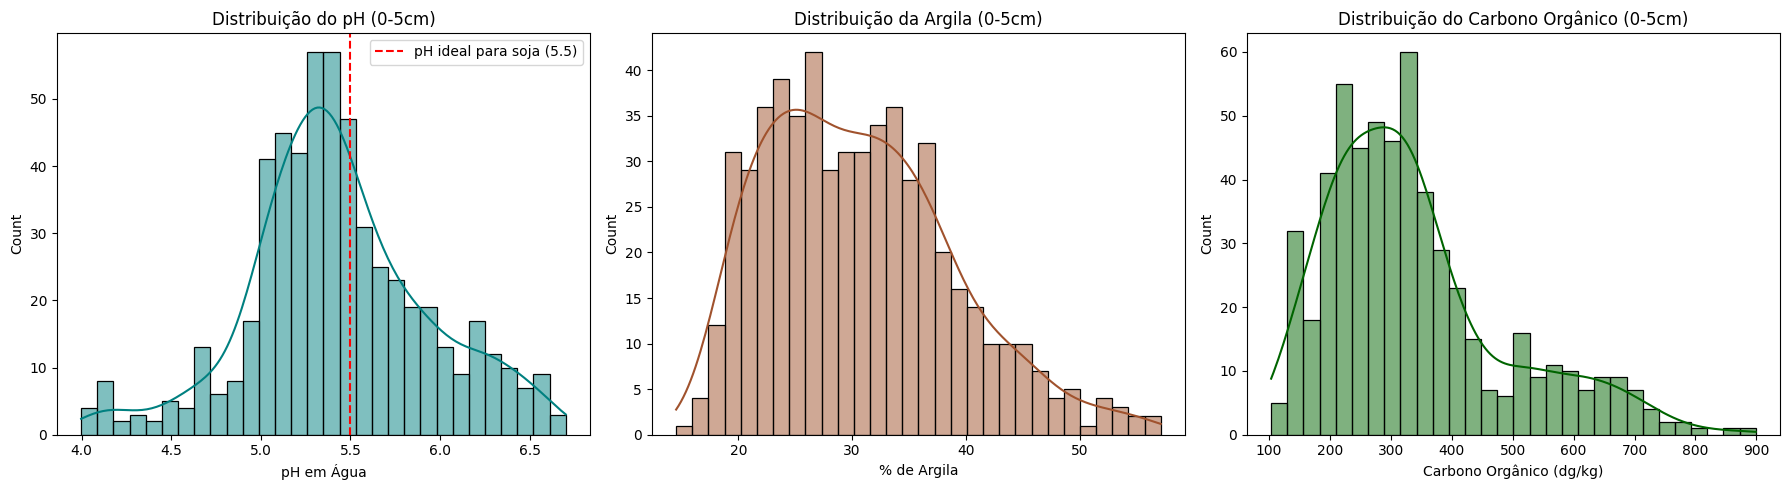

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Histograma de pH (0-5cm)
sns.histplot(df_solo['phh2o_0-5cm_mean'].dropna(), bins=30, kde=True, ax=axes[0], color='teal')
axes[0].set_title('Distribuição do pH (0-5cm)')
axes[0].set_xlabel('pH em Água')
axes[0].axvline(5.5, color='red', linestyle='--', label='pH ideal para soja (5.5)')
axes[0].legend()

# Histograma de Argila (0-5cm)
sns.histplot(df_solo['clay_0-5cm_mean'].dropna(), bins=30, kde=True, ax=axes[1], color='sienna')
axes[1].set_title('Distribuição da Argila (0-5cm)')
axes[1].set_xlabel('% de Argila')

# Histograma de Carbono Orgânico (0-5cm)
sns.histplot(df_solo['soc_0-5cm_mean'].dropna(), bins=30, kde=True, ax=axes[2], color='darkgreen')
axes[2].set_title('Distribuição do Carbono Orgânico (0-5cm)')
axes[2].set_xlabel('Carbono Orgânico (dg/kg)')

plt.tight_layout()
plt.show()

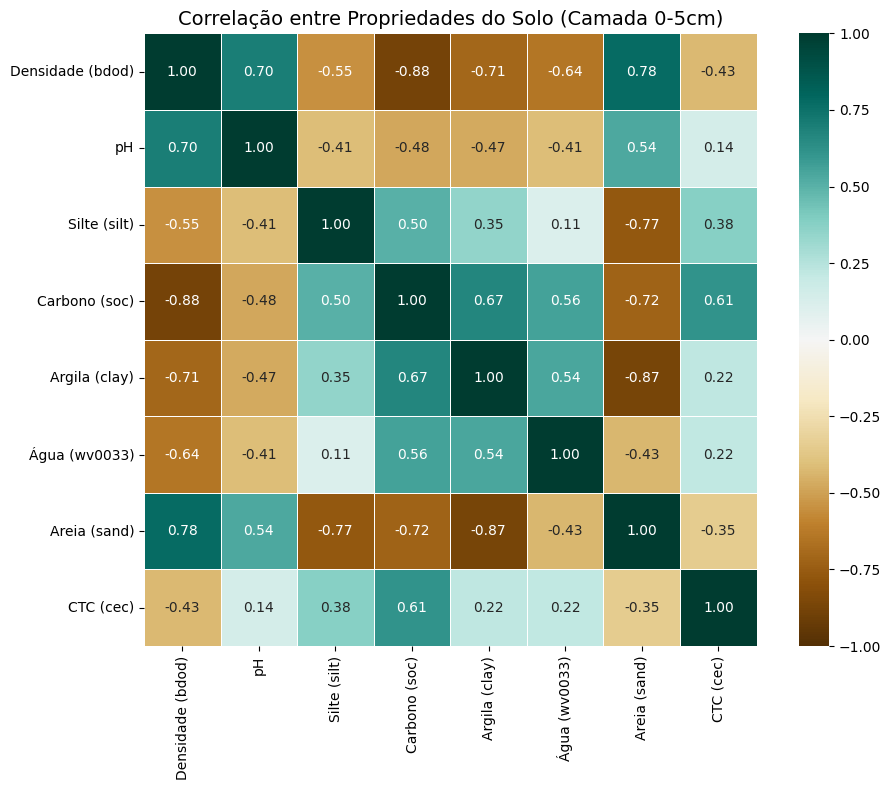

In [3]:
# Seleciona apenas as variáveis da camada 0-5cm
cols_05cm = [c for c in df_solo.columns if '0-5cm' in c]
corr_05cm = df_solo[cols_05cm].corr()

# Renomeia as colunas para ficarem legíveis no gráfico
nomes_limpos = {
    'bdod_0-5cm_mean': 'Densidade (bdod)',
    'cec_0-5cm_mean': 'CTC (cec)',
    'clay_0-5cm_mean': 'Argila (clay)',
    'phh2o_0-5cm_mean': 'pH',
    'sand_0-5cm_mean': 'Areia (sand)',
    'silt_0-5cm_mean': 'Silte (silt)',
    'soc_0-5cm_mean': 'Carbono (soc)',
    'wv0033_0-5cm_mean': 'Água (wv0033)'
}
corr_05cm = corr_05cm.rename(index=nomes_limpos, columns=nomes_limpos)

plt.figure(figsize=(10, 8))
sns.heatmap(corr_05cm, annot=True, fmt=".2f", cmap='BrBG', vmin=-1, vmax=1, square=True, linewidths=0.5)
plt.title('Correlação entre Propriedades do Solo (Camada 0-5cm)', fontsize=14)
plt.tight_layout()
plt.show()

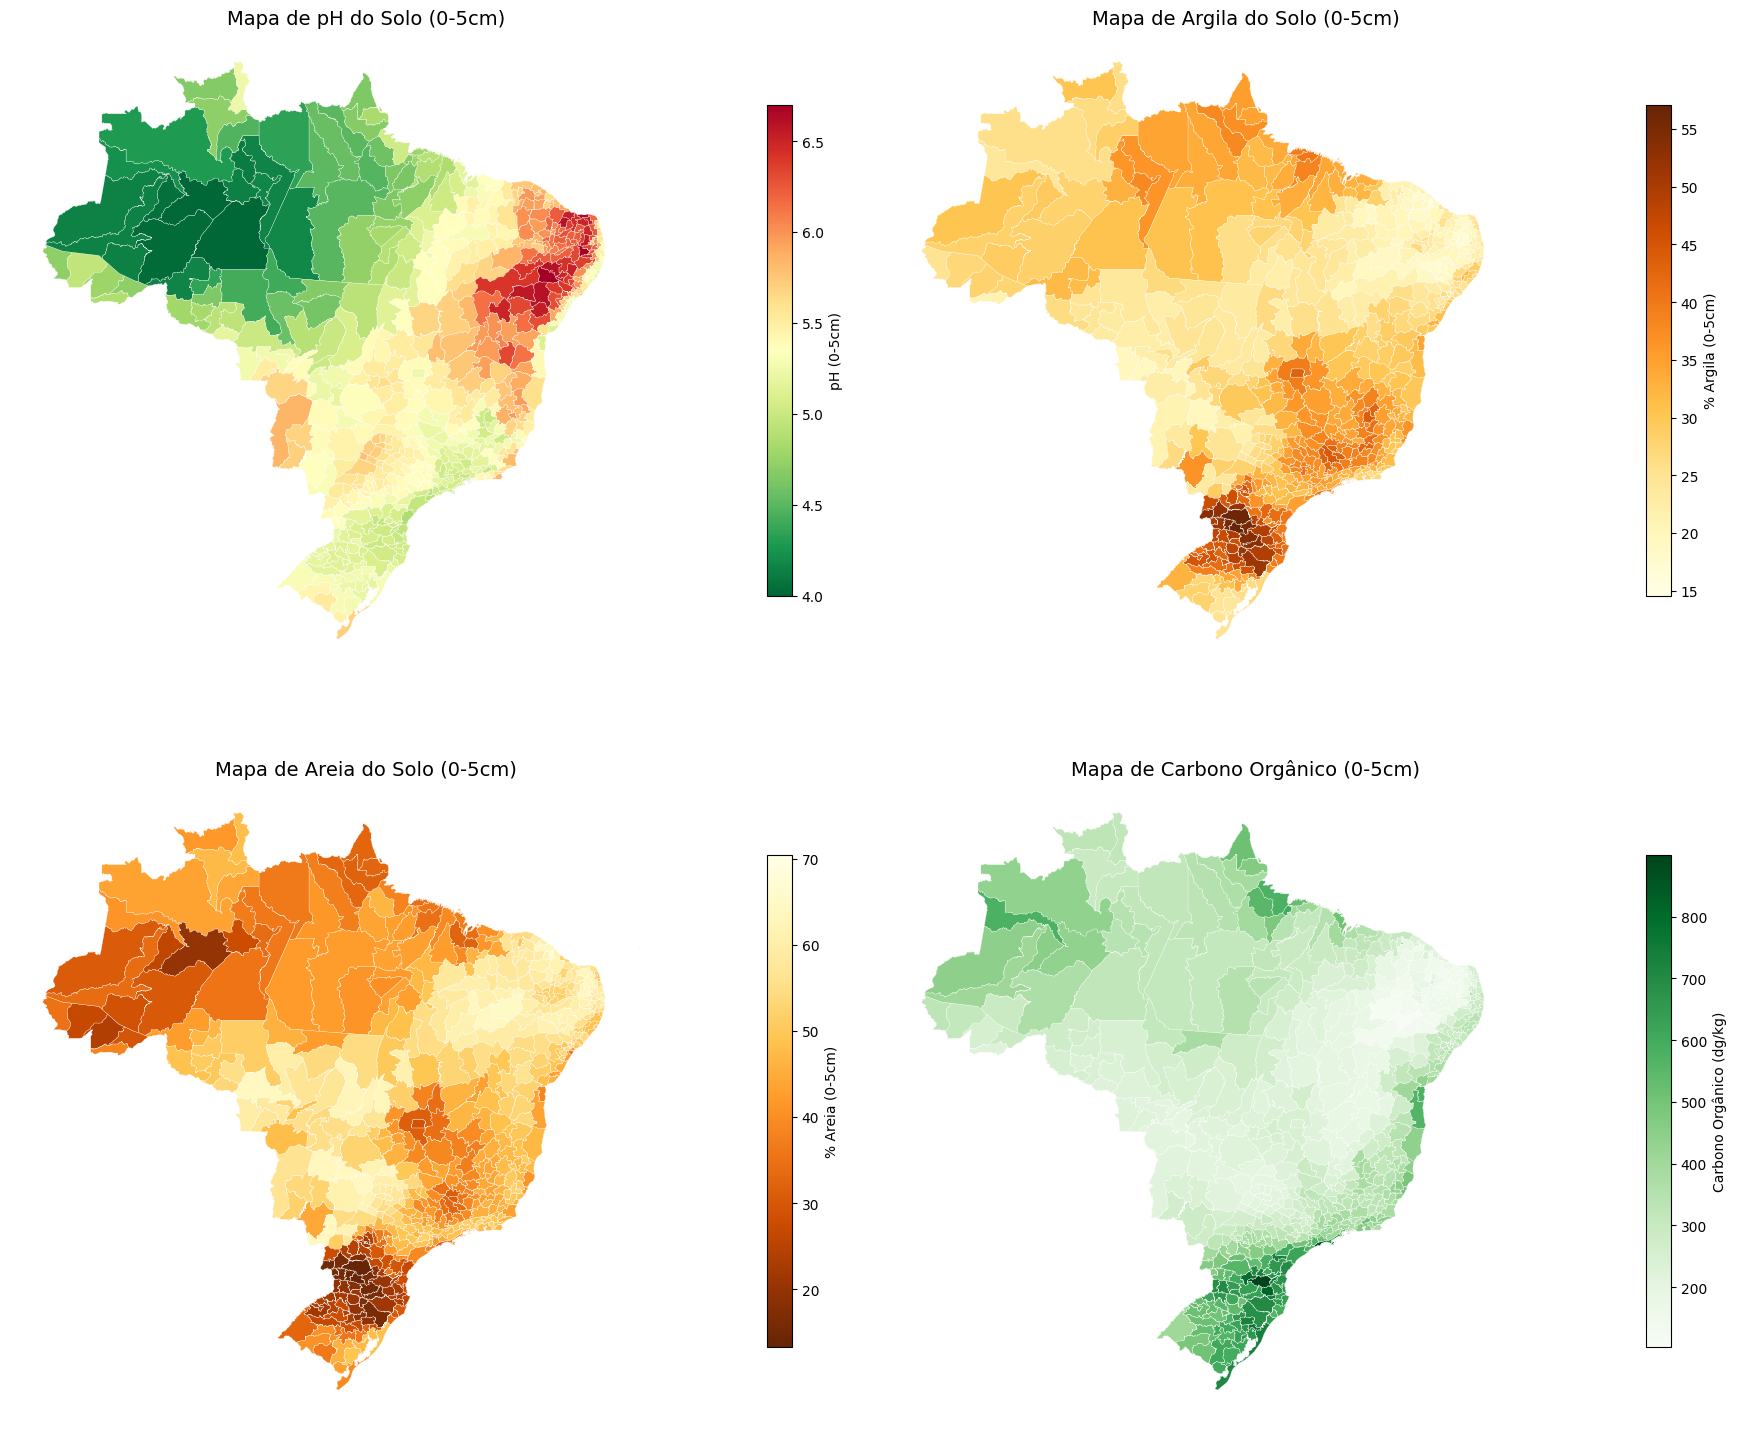

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(18, 16))
axes = axes.flatten()

# 1. Mapa de pH
gdf_plot.plot(column='phh2o_0-5cm_mean', cmap='RdYlGn_r', legend=True, 
              legend_kwds={'label': 'pH (0-5cm)', 'shrink': 0.6}, ax=axes[0], edgecolor='white', linewidth=0.2)
axes[0].set_title('Mapa de pH do Solo (0-5cm)', fontsize=14)
axes[0].axis('off')

# 2. Mapa de Argila
gdf_plot.plot(column='clay_0-5cm_mean', cmap='YlOrBr', legend=True, 
              legend_kwds={'label': '% Argila (0-5cm)', 'shrink': 0.6}, ax=axes[1], edgecolor='white', linewidth=0.2)
axes[1].set_title('Mapa de Argila do Solo (0-5cm)', fontsize=14)
axes[1].axis('off')

# 3. Mapa de Areia
gdf_plot.plot(column='sand_0-5cm_mean', cmap='YlOrBr_r', legend=True, 
              legend_kwds={'label': '% Areia (0-5cm)', 'shrink': 0.6}, ax=axes[2], edgecolor='white', linewidth=0.2)
axes[2].set_title('Mapa de Areia do Solo (0-5cm)', fontsize=14)
axes[2].axis('off')

# 4. Mapa de Carbono Orgânico
gdf_plot.plot(column='soc_0-5cm_mean', cmap='Greens', legend=True, 
              legend_kwds={'label': 'Carbono Orgânico (dg/kg)', 'shrink': 0.6}, ax=axes[3], edgecolor='white', linewidth=0.2)
axes[3].set_title('Mapa de Carbono Orgânico (0-5cm)', fontsize=14)
axes[3].axis('off')

plt.tight_layout()
plt.show()

Contagem de microrregiões por região:
Regiao
Nordeste        188
Sudeste         160
Sul              94
Norte            64
Centro-Oeste     52
Name: count, dtype: int64


/var/folders/j3/kppygfjs7xj9nbzbwjj9cjc80000gn/T/ipykernel_73217/3419638615.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=gdf_plot_regioes, x='Regiao', y='phh2o_0-5cm_mean', ax=axes[0], palette="Set2")
/var/folders/j3/kppygfjs7xj9nbzbwjj9cjc80000gn/T/ipykernel_73217/3419638615.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=gdf_plot_regioes, x='Regiao', y='clay_0-5cm_mean', ax=axes[1], palette="Set2")


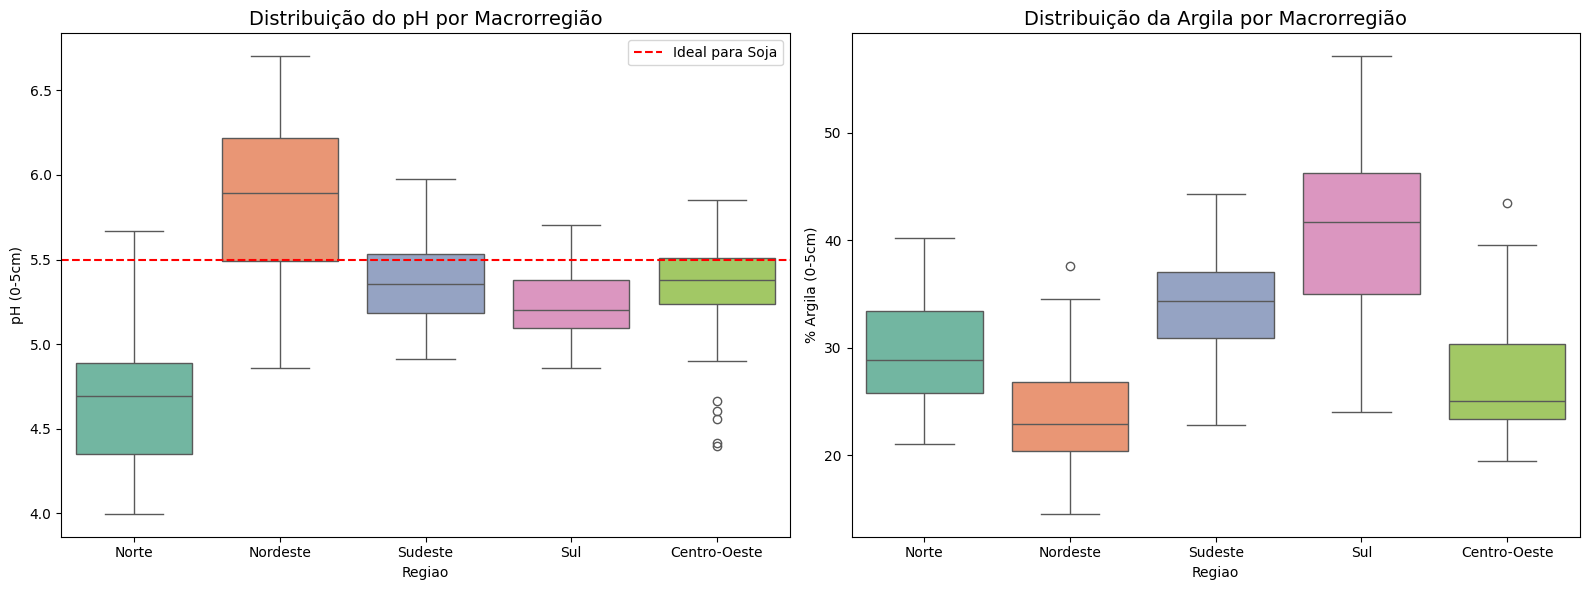

In [6]:
# Adiciona a região do Brasil (Norte, Nordeste, Sudeste, Sul, Centro-Oeste)
# O code_region no geobr vem como inteiro, mas às vezes pode vir como float ou string. Vamos padronizar.
gdf_plot['code_region'] = gdf_plot['code_region'].astype(float).astype(int).astype(str)

mapa_regioes = {'1': 'Norte', '2': 'Nordeste', '3': 'Sudeste', '4': 'Sul', '5': 'Centro-Oeste'}
gdf_plot['Regiao'] = gdf_plot['code_region'].map(mapa_regioes)

# Remove linhas onde a Regiao é nula para não quebrar o plot
gdf_plot_regioes = gdf_plot.dropna(subset=['Regiao']).copy()

print("Contagem de microrregiões por região:")
print(gdf_plot_regioes['Regiao'].value_counts())

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Boxplot de pH por Região
sns.boxplot(data=gdf_plot_regioes, x='Regiao', y='phh2o_0-5cm_mean', ax=axes[0], palette="Set2")
axes[0].set_title('Distribuição do pH por Macrorregião', fontsize=14)
axes[0].set_ylabel('pH (0-5cm)')
axes[0].axhline(5.5, color='red', linestyle='--', label='Ideal para Soja')
axes[0].legend()

# Boxplot de Argila por Região
sns.boxplot(data=gdf_plot_regioes, x='Regiao', y='clay_0-5cm_mean', ax=axes[1], palette="Set2")
axes[1].set_title('Distribuição da Argila por Macrorregião', fontsize=14)
axes[1].set_ylabel('% Argila (0-5cm)')

plt.tight_layout()
plt.show()